Deep Sigmoid Test Accuracy : 0.8450
Shallow ReLU Test Accuracy : 0.9800


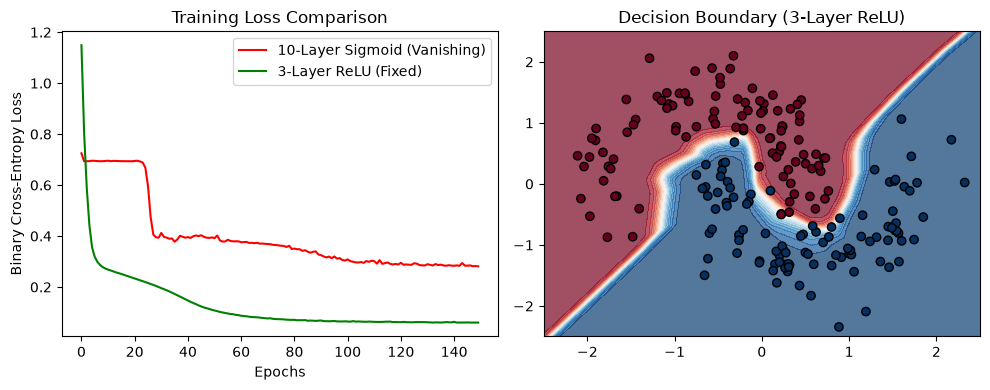

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Generate and prepare the Moons dataset
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ---------------------------------------------------------
# MODEL 1: Vanishing Gradient (Too Deep + Sigmoid)
# ---------------------------------------------------------
bad_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    # 10 hidden layers with sigmoid causes derivatives (<= 0.25) to multiply to ~0
    *[tf.keras.layers.Dense(32, activation='sigmoid') for _ in range(10)],
    tf.keras.layers.Dense(1, activation='sigmoid')
])

bad_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_bad = bad_model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=0
)

# ---------------------------------------------------------
# MODEL 2: Fixed (Reduced Complexity + ReLU + He Init)
# ---------------------------------------------------------
good_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    # Fewer layers (3 instead of 10) + ReLU (derivative = 1 for x > 0)
    tf.keras.layers.Dense(16, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(16, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(8, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

good_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_good = good_model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=0
)

# ---------------------------------------------------------
# 3. Compare Results & Visualize Loss
# ---------------------------------------------------------
print(f"Deep Sigmoid Test Accuracy : {bad_model.evaluate(X_test, y_test, verbose=0)[1]:.4f}")
print(f"Shallow ReLU Test Accuracy : {good_model.evaluate(X_test, y_test, verbose=0)[1]:.4f}")

plt.figure(figsize=(10, 4))

# Loss Curve Comparison
plt.subplot(1, 2, 1)
plt.plot(history_bad.history['loss'], label='10-Layer Sigmoid (Vanishing)', color='red')
plt.plot(history_good.history['loss'], label='3-Layer ReLU (Fixed)', color='green')
plt.title('Training Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()

# Decision Boundary of the Fixed Model
plt.subplot(1, 2, 2)
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
preds = good_model.predict(grid, verbose=0).reshape(xx.shape)

plt.contourf(xx, yy, preds, levels=20, cmap='RdBu', alpha=0.7)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='RdBu', edgecolors='k')
plt.title('Decision Boundary (3-Layer ReLU)')
plt.tight_layout()
plt.show()